# Figure 4 | A shared acquisition architecture across heterogeneous *K. pneumoniae* populations

In [1]:
from pathlib import Path
from collections import defaultdict
from functools import lru_cache
import hashlib
import json
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import spearmanr
from IPython.display import display, Markdown
import cartopy
import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader

# evostate paths: data in data/manuscript, analysis code in notebooks/manuscript/lib,
# figures written to results/rendered/manuscript.
REPO = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'data/manuscript').is_dir() and (p / 'notebooks/manuscript/lib').is_dir()), None)
if REPO is None:
    raise FileNotFoundError('Start Jupyter inside the evostate repository.')
MANUSCRIPT_DATA = REPO / 'data/manuscript'
MANUSCRIPT_LIB = REPO / 'notebooks/manuscript/lib'
RENDERED = REPO / 'results/rendered/manuscript'
ROOT = REPO
BASE = MANUSCRIPT_LIB
DATA = MANUSCRIPT_DATA / 'processed/microreact_kp_kleborate22'
RUN = MANUSCRIPT_DATA / 'results_repr_evo/microreact_kp_kleborate22'
OLD = RUN / 'figures_paper'
OUT = RENDERED / 'figure4'
SOURCE = OUT / 'source_data'
CACHE = MANUSCRIPT_DATA / 'results_repr_evo/manuscript/figure4/cache'
for p in [OUT, SOURCE, CACHE]:
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(BASE / 'analysis_repr_evo'))
import evoamr_story as st
import paper_figure_kp as kp
import hypertraps_compare as hc

SEED = 0
N_BOOT = 2000
N_PERM = 2000
N_WALKS = 1500
MIN_SINGLE = 20
MIN_LINEAGE_GAINS = 50
MAX_LINEAGES = 28
MIN_COUNTRY_EDGES = 30
MIN_FEATURE_GAINS = 5
TOP_ST = ['ST258', 'ST11', 'ST15', 'ST147', 'ST512', 'ST307']
TOP_COUNTRY = ['USA', 'China', 'UK', 'Italy', 'Thailand', 'India']
BLUE, ORANGE, GREY = '#246998', '#c87836', '#687780'
CONT_COLORS = {'Africa': '#3d8fb1', 'America': '#e39746', 'Asia': '#47975c', 'Europe': '#bb5b68', 'Oceania': '#936ca6', 'Unknown': '#a6a6a6'}
mpl.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8, 'xtick.labelsize': 7, 'ytick.labelsize': 7, 'pdf.fonttype': 42, 'ps.fonttype': 42, 'axes.spines.top': False, 'axes.spines.right': False, 'savefig.dpi': 240})
INPUTS, FIGURES = {}, []

def digest(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def track(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f'Required input missing: {path}')
    INPUTS[str(path.relative_to(ROOT)) if path.is_relative_to(ROOT) else str(path)] = digest(path)
    return path

def read_csv(path, **kwargs):
    return pd.read_csv(track(path), **kwargs)

def export(frame, name, index=False):
    frame.to_csv(SOURCE / (name + '.csv'), index=index)

def finish(fig, name):
    for ext in ['pdf', 'png']:
        fig.savefig(OUT / f'{name}.{ext}', bbox_inches='tight', facecolor='white')
    FIGURES.append(name)
    display(fig)
    plt.close(fig)

for name in ['evoamr_story.py', 'paper_figure_kp.py', 'hypertraps_compare.py']:
    track(BASE / 'analysis_repr_evo' / name)
print('Output:', OUT)

Output: /apdcephfs_qy3/share_2932069/ziyiyang/1-antibiotic_resistance/EvoAMR/evoamr/evostate/results/rendered/manuscript/figure4


## 1. Cohort and split audit

In [2]:
MANIFEST = json.loads(track(DATA / 'transitions/manifest.json').read_text())
FEATURES = MANIFEST['feature_columns']
L = len(FEATURES)
assert L == 22
SHORT = kp.kp_short_map(FEATURES)
SAMPLES = read_csv(DATA / 'samples.csv', dtype={'sample_id': str, 'ST': str})
BARCODE = read_csv(DATA / 'category_barcode.csv', dtype={'sample_id': str})
assert SAMPLES.sample_id.is_unique and BARCODE.sample_id.is_unique
assert set(SAMPLES.sample_id) == set(BARCODE.sample_id)
assert np.isin(BARCODE[FEATURES].to_numpy(), [0, 1]).all()
SAMPLES['Country'] = SAMPLES.Country.fillna('Unknown').replace({'unknown': 'Unknown', '': 'Unknown'})
SAMPLES['year_numeric'] = pd.to_numeric(SAMPLES.Year, errors='coerce')
for coordinate in ['latitude', 'longitude']:
    SAMPLES[coordinate] = pd.to_numeric(SAMPLES[coordinate], errors='coerce')
PROFILE_COUNTS = (BARCODE[FEATURES].astype(str).agg(''.join, axis=1).value_counts().rename_axis('profile').reset_index(name='n_genomes'))
PROFILE_COUNTS['rank'] = np.arange(1, len(PROFILE_COUNTS) + 1)
assert PROFILE_COUNTS.n_genomes.sum() == len(SAMPLES)
COUNTS = SAMPLES.groupby('Country').agg(n_genomes=('sample_id', 'size'), latitude=('latitude', 'median'), longitude=('longitude', 'median')).sort_values('n_genomes', ascending=False).rename_axis('key').reset_index()
COUNTS['log10_n_genomes'] = np.log10(COUNTS.n_genomes)
YEARS = pd.crosstab(SAMPLES.Country, SAMPLES.year_numeric).sort_index(axis=1)
UNKNOWN_YEARS = SAMPLES.groupby('Country').year_numeric.apply(lambda x: x.isna().sum())
export(COUNTS, 'sampling_countries')
export(YEARS, 'sampling_country_year', index=True)
export(UNKNOWN_YEARS.rename('n_unknown_year').reset_index(), 'sampling_unknown_year')
export(PROFILE_COUNTS, 'all_resistance_profiles')

T = read_csv(DATA / 'transitions/transitions.csv', dtype=str).fillna('')
SRC = np.array([list(s) for s in T.src_state], dtype=np.int8)
DST = np.array([list(s) for s in T.dest_state], dtype=np.int8)
TRUTH = DST - SRC
NGAIN = TRUTH.sum(1)
GROUP = T.group_id.to_numpy(str)
assert SRC.shape == DST.shape == (len(T), L)
assert np.isin(TRUTH, [0, 1]).all() and np.all(NGAIN > 0)
assert np.array_equal(NGAIN, T.n_gained.astype(int))
HISTORY = json.loads(track(RUN / 'grouped_cv/eval/eval_summary.json').read_text())

def historical_splits(labels, folds, seed):
    rng = np.random.default_rng(seed)
    groups = defaultdict(list)
    for i, g in enumerate(labels):
        groups[g].append(i)
    target = max(1, len(labels) // (folds * 3))
    blocks = []
    for indices in groups.values():
        indices = list(indices)
        rng.shuffle(indices)
        blocks.extend(indices[j:j + target] for j in range(0, len(indices), target))
    rng.shuffle(blocks)
    members, sizes = [[] for _ in range(folds)], [0] * folds
    for block in sorted(blocks, key=len, reverse=True):
        f = int(np.argmin(sizes))
        members[f].extend(block)
        sizes[f] += len(block)
    return [(np.setdiff1d(np.arange(len(labels)), sorted(m)), np.array(sorted(m))) for m in members]

FOLD = np.full(len(T), -1)
LL = {m: np.full(len(T), np.nan) for m in ['TS_pretrained', 'B1_prevalence']}
fold_audit = []
for fold, (train, test) in enumerate(historical_splits(GROUP, int(HISTORY['folds']), SEED)):
    file = RUN / 'grouped_cv/eval/predictions' / f'predictions_fold_{fold:02d}.npz'
    with np.load(track(file), allow_pickle=False) as z:
        if not np.array_equal(SRC[test], z['src']) or not np.array_equal(TRUTH[test], z['truth']):
            raise ValueError(f'Fold {fold}: split alignment failed; do not assign ST labels.')
        for method in LL:
            prob = z['p__' + method].astype(float)
            assert np.isfinite(prob).all() and (prob >= 0).all()
            assert np.allclose(prob.sum(1), 1, atol=1e-5)
            assert np.allclose(prob[SRC[test] > 0], 0, atol=1e-8)
            single = NGAIN[test] == 1
            ix = TRUTH[test][single].argmax(1)
            LL[method][test[single]] = np.log(np.maximum(prob[single][np.arange(single.sum()), ix], 1e-12))
        ref = (TRUTH[train].sum(0) + 1e-6)[None, :] * (1 - SRC[test])
        ref /= ref.sum(1, keepdims=True)
        assert np.max(np.abs(ref - z['p__B1_prevalence'])) < 1e-5
    FOLD[test] = fold
    fold_audit.append({'fold': fold, 'n_train': len(train), 'n_test': len(test), 'overlapping_STs': ';'.join(sorted(set(GROUP[train]) & set(GROUP[test])))})
assert (FOLD >= 0).all()
AUDIT_ST = pd.DataFrame({'ST': GROUP, 'fold': FOLD, 'single': NGAIN == 1}).groupby('ST').agg(n_edges=('fold', 'size'), n_test_folds=('fold', 'nunique'), n_single=('single', 'sum'))
SPLIT_ST = AUDIT_ST.index[AUDIT_ST.n_test_folds > 1].tolist()
EDGE = pd.DataFrame({'row_id': np.arange(len(T)), 'ST': GROUP, 'fold': FOLD, 'single': NGAIN == 1, 'held_out': ~np.isin(GROUP, SPLIT_ST), 'logl_evo': LL['TS_pretrained'], 'logl_baseline': LL['B1_prevalence']})
EDGE['delta'] = EDGE.logl_evo - EDGE.logl_baseline
export(EDGE, 'heldout_edge_log_likelihood')
export(AUDIT_ST, 'lineage_split_audit', index=True)
export(pd.DataFrame(fold_audit), 'fold_audit')
print(f'{len(SAMPLES):,} genomes; {len(PROFILE_COUNTS):,} distinct profiles; {len(T):,} inferred transitions.')
print('Excluded from strict held-out evaluation:', SPLIT_ST)

11,260 genomes; 2,464 distinct profiles; 9,026 inferred transitions.
Excluded from strict held-out evaluation: ['ST11', 'ST258']


## 2. Performance layer and threshold sensitivity

In [3]:
def bootstrap_mean(values, seed=SEED):
    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    means = values[rng.integers(0, len(values), size=(N_BOOT, len(values)))].mean(1)
    return tuple(np.quantile(means, [.025, .975]))

rows = []
for g, frame in EDGE[EDGE.single].groupby('ST', sort=True):
    lo, hi = bootstrap_mean(frame.delta)
    rows.append({'ST': g, 'n_single': len(frame), 'n_edges': int(AUDIT_ST.loc[g, 'n_edges']), 'held_out': bool(frame.held_out.all()), 'gain': frame.delta.mean(), 'logl_evo': frame.logl_evo.mean(), 'logl_baseline': frame.logl_baseline.mean(), 'ci_low': lo, 'ci_high': hi})
LINEAGES = pd.DataFrame(rows)
ELIGIBLE = LINEAGES[LINEAGES.held_out].copy()
MAIN_B = ELIGIBLE[ELIGIBLE.n_single >= MIN_SINGLE].sort_values('gain', ascending=False).reset_index(drop=True)
if MAIN_B.empty:
    raise ValueError('No strictly held-out lineages meet the support threshold.')
B_MEAN = MAIN_B.gain.mean()
B_CI = bootstrap_mean(MAIN_B.gain)
B_POS = int((MAIN_B.gain > 0).sum())
SENSITIVITY = []
for minimum in [10, 20, 30, 50]:
    f = ELIGIBLE[ELIGIBLE.n_single >= minimum].sort_values('gain', ascending=False)
    lo, hi = bootstrap_mean(f.gain)
    SENSITIVITY.append({'minimum_single': minimum, 'n_ST': len(f), 'n_single': int(f.n_single.sum()), 'n_positive': int((f.gain > 0).sum()), 'positive_fraction': (f.gain > 0).mean(), 'ST_equal_mean': f.gain.mean(), 'ci_low': lo, 'ci_high': hi, 'edge_weighted_mean': np.average(f.gain, weights=f.n_single) if len(f) else np.nan})
SENSITIVITY = pd.DataFrame(SENSITIVITY)
ST_SAMPLES = SAMPLES.ST.value_counts()
ELIGIBLE['n_genomes'] = ELIGIBLE.ST.map(ST_SAMPLES).fillna(0).astype(int)
SCATTER_MIN_SINGLE = 5
SCATTER_ST = ELIGIBLE[(ELIGIBLE.n_single >= SCATTER_MIN_SINGLE) & (ELIGIBLE.n_genomes > 0)].copy()
assert set(MAIN_B.ST).issubset(set(SCATTER_ST.ST))
CORRELATIONS = []
CORRELATION_SENSITIVITY = []
for minimum in [1, 2, 5, 10]:
    cohort = ELIGIBLE[(ELIGIBLE.n_single >= minimum) & (ELIGIBLE.n_genomes > 0)]
    for column in ['n_genomes', 'n_single']:
        rho, p = spearmanr(cohort[column], cohort.gain)
        result = {'support_measure': column, 'minimum_single': minimum, 'scope': f'strictly held-out STs with >={minimum} single gains and recorded genome count', 'n_ST': len(cohort), 'spearman_rho': rho, 'p_value': p}
        CORRELATION_SENSITIVITY.append(result)
        if minimum == SCATTER_MIN_SINGLE:
            CORRELATIONS.append(result)
export(SCATTER_ST, 'S2_CD_support_scatter')
export(pd.DataFrame(CORRELATION_SENSITIVITY), 'support_gain_correlation_sensitivity')
export(LINEAGES, 'all_lineage_performance')
export(MAIN_B, 'main_B_lineage_performance')
export(SENSITIVITY, 'support_threshold_sensitivity')
export(pd.DataFrame(CORRELATIONS), 'support_gain_correlations')
print(f'{B_POS}/{len(MAIN_B)} positive; ST-equal delta LL = {B_MEAN:+.3f} [{B_CI[0]:.3f}, {B_CI[1]:.3f}]')
display(SENSITIVITY.round(4))

24/25 positive; ST-equal delta LL = +0.417 [0.318, 0.527]


,minimum_single,n_ST,n_single,n_positive,positive_fraction,ST_equal_mean,ci_low,ci_high,edge_weighted_mean
0,10,42,1781,39,0.9286,0.3911,0.2887,0.4884,0.3495
1,20,25,1561,24,0.9600,0.4168,0.3177,0.5274,0.3504
2,30,17,1372,16,0.9412,0.3408,0.2448,0.4460,0.3213
3,50,10,1101,10,1.0000,0.3127,0.2310,0.4017,0.3081


## 3. Shared and population-associated acquisition order

In [4]:
TS = st.load_transition_set(str(DATA / 'transitions/transitions.csv'), str(DATA))
assert list(TS.feature_names) == FEATURES
GLOBAL_EMP = st.empirical_bubble_matrix(TS)
GLOBAL_MODEL = read_csv(OLD / 'kp_bubble_TS_pretrained.csv', index_col=0).reindex(FEATURES)
STEPS = np.arange(1, L + 1)

def check_bubble(frame, complete=False):
    assert list(frame.index) == FEATURES
    assert list(frame.columns) == [f'step{i}' for i in STEPS]
    a = frame.to_numpy(float)
    assert np.isfinite(a).all() and (a >= 0).all()
    totals = a.sum(1)
    assert np.all(np.isclose(totals, 1) | np.isclose(totals, 0))
    if complete:
        assert np.allclose(totals, 1) and np.allclose(a.sum(0), 1)

def expected(frame):
    mass = frame.sum(1)
    return frame.mul(STEPS, axis=1).sum(1).div(mass.where(mass > 0))

check_bubble(GLOBAL_EMP)
check_bubble(GLOBAL_MODEL, complete=True)
GLOBAL_EO = expected(GLOBAL_EMP)
ORDER = GLOBAL_EO.sort_values().index.tolist()
MODEL_ORDER = expected(GLOBAL_MODEL).sort_values().index.tolist()
FEATURE_COLORS = dict(zip(ORDER, plt.get_cmap('turbo')(np.linspace(.08, .92, L))))
LIN_BUBBLES, LIN_META = kp.lineage_bubbles(TS, min_events=MIN_LINEAGE_GAINS, max_groups=MAX_LINEAGES)
LIN_ORDER = LIN_META.sort_values('n_gain_events', ascending=False).group_id.tolist()
LIN_EO = pd.DataFrame({g: expected(b) for g, b in LIN_BUBBLES.items()})
LIN_SUPPORT = pd.DataFrame({g: TRUTH[GROUP == g].sum(0) for g in LIN_ORDER}, index=FEATURES)
LDEV_RAW = LIN_EO.sub(GLOBAL_EO, axis=0).reindex(index=ORDER, columns=LIN_ORDER)
LDEV = LDEV_RAW.copy()
assert np.array_equal(LDEV.isna(), LIN_SUPPORT.reindex_like(LDEV).eq(0))
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list
from scipy.spatial.distance import pdist
CLUSTER_MIN_COVERAGE = .70
cluster_supported = LDEV.where(LIN_SUPPORT.reindex_like(LDEV) >= MIN_FEATURE_GAINS)
cluster_coverage = cluster_supported.notna().mean(axis=1)
cluster_features = cluster_coverage.index[cluster_coverage >= CLUSTER_MIN_COVERAGE].tolist()
if len(cluster_features) < 3:
    raise ValueError('Too few broadly supported features for lineage clustering')
cluster_input = cluster_supported.loc[cluster_features].T
cluster_missing = cluster_input.isna()
cluster_input = cluster_input.fillna(cluster_input.median(axis=0))
cluster_input = cluster_input.loc[:, cluster_input.std(axis=0) > 1e-12]
if cluster_input.shape[1] < 3 or (cluster_input.std(axis=1) <= 1e-12).any():
    raise ValueError('Insufficient variation for correlation-distance clustering')
cluster_distances = pdist(cluster_input.to_numpy(), metric='correlation')
assert np.isfinite(cluster_distances).all()
LINEAGE_LINKAGE = linkage(cluster_distances, method='average', optimal_ordering=True)
CLUSTER_ST_LABELS = cluster_input.index.tolist()
LIN_ORDER = [CLUSTER_ST_LABELS[i] for i in leaves_list(LINEAGE_LINKAGE)]
LDEV = LDEV.loc[:, LIN_ORDER]
export(cluster_input, 'lineage_clustering_input', index=True)
export(cluster_missing[cluster_input.columns], 'lineage_clustering_imputed_cells', index=True)
export(pd.DataFrame(LINEAGE_LINKAGE, columns=['left', 'right', 'distance', 'n_members']), 'lineage_clustering_linkage')
export(pd.DataFrame({'ST': LIN_ORDER, 'position': np.arange(len(LIN_ORDER))}), 'lineage_cluster_order')
LINEAGE_CLUSTER_INFO = {'interpretation': 'acquisition deviation similarity, not genetic phylogeny', 'distance': 'correlation', 'linkage': 'average; optimal leaf ordering', 'minimum_local_gains': MIN_FEATURE_GAINS, 'minimum_ST_coverage': CLUSTER_MIN_COVERAGE, 'features': cluster_input.columns.tolist(), 'imputed_cells': int(cluster_missing[cluster_input.columns].sum().sum()), 'imputation': 'feature median among supported STs, clustering only; display unchanged'}


CMETA = read_csv(OLD / 'kp_country_meta.csv')
CMETA = CMETA[CMETA.n_transitions >= MIN_COUNTRY_EDGES].copy()
COUNTRY_BUBBLES, COUNTRY_SUPPORT, C_AUDIT = {}, {}, []
for row in CMETA.itertuples():
    path = DATA / 'transitions_by_country' / row.safe_name / 'transitions.csv'
    track(path)
    ts_country = st.load_transition_set(str(path), str(DATA))
    assert list(ts_country.feature_names) == FEATURES
    if ts_country.n < MIN_COUNTRY_EDGES:
        raise ValueError(f'{row.key}: cached country inclusion is stale.')
    COUNTRY_BUBBLES[row.key] = st.empirical_bubble_matrix(ts_country)
    COUNTRY_SUPPORT[row.key] = (ts_country.dest - ts_country.src).sum(0)
    C_AUDIT.append({'country': row.key, 'n_transitions': ts_country.n, 'n_gain_events': int((ts_country.dest - ts_country.src).sum()), 'cache_n_transitions': row.n_transitions})
C_AUDIT = pd.DataFrame(C_AUDIT).set_index('country')
assert np.array_equal(C_AUDIT.n_transitions, C_AUDIT.cache_n_transitions)
CMETA['n_gain_events'] = CMETA.key.map(C_AUDIT.n_gain_events)
CABS = pd.DataFrame({g: expected(b) for g, b in COUNTRY_BUBBLES.items()})
CDEV_RAW = CABS.sub(GLOBAL_EO, axis=0)
OLD_CDEV = read_csv(OLD / 'kp_country_order_deviation.csv', index_col=0)
assert set(OLD_CDEV.columns) == set(CDEV_RAW.columns)
CDEV_RAW = CDEV_RAW.reindex(index=OLD_CDEV.index, columns=OLD_CDEV.columns)
CACHE_DIFFERENCE = float(np.nanmax(np.abs(CDEV_RAW - OLD_CDEV)))
if not np.allclose(CDEV_RAW, OLD_CDEV, equal_nan=True):
    warnings.warn(f'Old country deviations differ (max={CACHE_DIFFERENCE:.3g}); using recomputed values.')
C_SUPPORT = pd.DataFrame(COUNTRY_SUPPORT, index=FEATURES)
CONTINENT = CMETA.set_index('key').continent.fillna('Unknown').to_dict()
CCORR = read_csv(OLD / 'kp_country_pc_correlation.csv')
CCORR_OK = CCORR[(CCORR.n_gain_events >= 30) & (CCORR['class'] != 'insufficient data')].reset_index(drop=True)
DEV_OK = OLD_CDEV.loc[CCORR_OK.feature.tolist()]
assert np.allclose(CDEV_RAW, OLD_CDEV, equal_nan=True), 'Country source changed; reconcile with figure_D_country before plotting.'
reference_fig, reference_slot = plt.subplots()
try:
    reference_ax = kp.panel_order_deviation_map(reference_slot, DEV_OK, SHORT, kp.kp_class_map(FEATURES), meta=CMETA, corr=CCORR_OK, column_mode='continent', annotate_cluster_test=False)
    COUNTRY_ORDER = [tick.get_text() for tick in reference_ax.get_xticklabels()]
    COUNTRY_VMAX = float(reference_ax.images[0].get_clim()[1])
    ORIGINAL_COUNTRY_D = DEV_OK.loc[:, COUNTRY_ORDER]
    assert np.allclose(reference_ax.images[0].get_array().filled(np.nan), ORIGINAL_COUNTRY_D, equal_nan=True)
finally:
    plt.close(reference_fig)
CDEV = OLD_CDEV.reindex(index=ORDER, columns=COUNTRY_ORDER)
COUNTRY_MAIN = CDEV.copy()
assert COUNTRY_MAIN.shape == (22, len(COUNTRY_ORDER))
pd.testing.assert_frame_equal(COUNTRY_MAIN, CDEV)
COUNTRY_SUPPORT_MASKED = CDEV.where(C_SUPPORT.reindex_like(CDEV) >= MIN_FEATURE_GAINS)
CSCORES, _, CEVR = kp.bubble_pca(COUNTRY_BUBBLES, n_pc=3)
CLUSTER_TEST = kp.deviation_cluster_vs_continent(ORIGINAL_COUNTRY_D, CMETA, n_perm=N_PERM, seed=0)
LEGACY_CLUSTER = json.loads(track(OLD / 'kp_country_cluster_vs_continent.json').read_text())
LEGACY_RECOMPUTED = kp.deviation_cluster_vs_continent(DEV_OK, CMETA, n_perm=N_PERM, seed=1)
assert np.isclose(LEGACY_CLUSTER['ari'], LEGACY_RECOMPUTED['ari'])
assert np.isclose(LEGACY_CLUSTER['p_value'], LEGACY_RECOMPUTED['p_value'])
CLUSTER_AUDIT = pd.DataFrame([dict(source='original_notebook_summary', seed=1, n_features=len(DEV_OK), **{k: LEGACY_CLUSTER[k] for k in ['n', 'k', 'ari', 'p_value', 'n_perm']}), dict(source='original_notebook_test_reproduced', seed=1, n_features=len(DEV_OK), **{k: LEGACY_RECOMPUTED[k] for k in ['n', 'k', 'ari', 'p_value', 'n_perm']}), dict(source='original_plot_D_annotation_reproduced', seed=0, n_features=len(DEV_OK), **{k: CLUSTER_TEST[k] for k in ['n', 'k', 'ari', 'p_value', 'n_perm']})])
export(CLUSTER_AUDIT, 'country_cluster_legacy_reconciliation')
export(ORIGINAL_COUNTRY_D, 'original_country_D_reproduced', index=True)
export(CCORR_OK, 'original_country_character_filter')
print('Original notebook test and plot annotation both reproduced; Fig.4F uses the plot annotation protocol.')
PCA_TEST = kp.group_structure_test(CSCORES, CMETA.set_index('key').continent, n_perm=N_PERM, seed=1)
for name, frame in [('global_empirical_order_distribution', GLOBAL_EMP), ('global_model_order_distribution', GLOBAL_MODEL), ('lineage_expected_order', LIN_EO), ('lineage_gain_support', LIN_SUPPORT), ('main_D_lineage_deviation', LDEV), ('country_expected_order', CABS), ('country_gain_support', C_SUPPORT), ('country_deviation_unmasked', CDEV_RAW), ('country_deviation_masked', COUNTRY_SUPPORT_MASKED), ('main_E_country_deviation', COUNTRY_MAIN), ('country_pca_scores', CSCORES), ('country_transition_audit', C_AUDIT)]:
    export(frame, name, index=True)
export(LIN_META, 'lineage_dynamics_support')
export(CMETA, 'country_dynamics_support')
print('Cluster/continent:', {k: v for k, v in CLUSTER_TEST.items() if k != 'clusters'})
print('Separate PCA score group test:', PCA_TEST)
SUPPORT_AUDIT = []
for panel, matrix, counts in [('main_D', LDEV, LIN_SUPPORT), ('main_E', COUNTRY_MAIN, C_SUPPORT), ('S4_D', CDEV, C_SUPPORT)]:
    counts = counts.reindex(index=matrix.index, columns=matrix.columns)
    assert np.array_equal(matrix.isna(), counts.eq(0))
    flags = pd.DataFrame(np.where(counts.eq(0), 'no_reconstructed_gains', np.where(counts.lt(MIN_FEATURE_GAINS), 'low_support', 'supported')), index=matrix.index, columns=matrix.columns)
    export(flags, panel + '_support_status', index=True)
    SUPPORT_AUDIT.append({'panel': panel, 'total_cells': matrix.size, 'no_gain_grey': int(counts.eq(0).sum().sum()), 'low_support_colored': int((counts.gt(0) & counts.lt(MIN_FEATURE_GAINS)).sum().sum()), 'supported_colored': int(counts.ge(MIN_FEATURE_GAINS).sum().sum())})
export(pd.DataFrame(SUPPORT_AUDIT), 'heatmap_support_audit')


Original notebook test and plot annotation both reproduced; Fig.4F uses the plot annotation protocol.
Cluster/continent: {'n': 29, 'k': 5, 'ari': -0.056785155376704685, 'p_value': 0.9025487256371814, 'n_perm': 2000, 'cluster_sizes': [5, 2, 4, 5, 13]}
Separate PCA score group test: {'n': 28, 'k': 4, 'F': 2.706421761807705, 'p_value': 0.006496751624187906, 'r2': 0.2527849006903633, 'n_perm': 2000}


## 4. Shared drawing functions

In [5]:
MAP_PATH = MANUSCRIPT_DATA / 'natural_earth/ne_110m_admin_0_countries.shp'
if not MAP_PATH.is_file():
    raise FileNotFoundError(f'Local Natural Earth map missing: {MAP_PATH}. Configure cartopy data_dir before plotting.')
WORLD = list(shpreader.Reader(str(MAP_PATH)).records())
for suffix in ['.shp', '.shx', '.dbf', '.prj']:
    p = MAP_PATH.with_suffix(suffix)
    if p.exists():
        track(p)
ALIASES = {'United States of America': 'USA', 'United States': 'USA', 'United Kingdom': 'UK', 'Russian Federation': 'Russia', 'Viet Nam': 'Vietnam', 'Czechia': 'Czech Republic', 'United Republic of Tanzania': 'Tanzania', 'Dem. Rep. Congo': 'Democratic Republic of the Congo', 'Democratic Republic of the Congo': 'Democratic Republic of the Congo', 'Republic of Korea': 'South Korea', 'S. Sudan': 'South Sudan', 'Lao PDR': 'Laos', "Côte d'Ivoire": "Cote d'Ivoire"}

def tidy(ax):
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(length=2.5, pad=2)

def title(ax, label, text):
    ax.set_title(f'{label}  {text}', loc='left', fontweight='bold', pad=10)

def map_panel(ax, counts, colorbar=True):
    values = counts.set_index('key').n_genomes.to_dict()
    norm = mpl.colors.Normalize(0, max(3, np.log10(max(values.values()))))
    cmap = plt.get_cmap('inferno_r')
    matched = set()
    for rec in WORLD:
        keys = [rec.attributes.get(k, '') for k in ['ADMIN', 'NAME_LONG', 'NAME', 'SOVEREIGNT']]
        key = next((ALIASES.get(k, k) for k in keys if ALIASES.get(k, k) in values), None)
        color = cmap(norm(np.log10(values[key]))) if key is not None else '#eceeef'
        if key is not None:
            matched.add(key)
        ax.add_geometries([rec.geometry], ccrs.PlateCarree(), facecolor=color, edgecolor='white', linewidth=.25)
    ax.set_global()
    ax.spines['geo'].set_visible(False)
    if colorbar:
        cb = ax.figure.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, orientation='horizontal', fraction=.045, pad=.02, shrink=.65)
        cb.set_label('log10(number of genomes)', fontsize=7)
    return matched

def upset(fig, spec, n=14, full=False):
    sub = spec.subgridspec(2, 1, height_ratios=[1, 2.7 if full else 2.2], hspace=.06)
    top, bottom = fig.add_subplot(sub[0]), fig.add_subplot(sub[1])
    f = PROFILE_COUNTS.head(n)
    matrix = np.array([list(s) for s in f.profile], dtype=int).T
    weights = matrix @ f.n_genomes.to_numpy()
    rows = np.argsort(-weights, kind='stable')
    if not full:
        rows = rows[weights[rows] > 0]
    x = np.arange(len(f))
    top.bar(x, f.n_genomes, color=BLUE, width=.82)
    top.set_ylabel('Genomes')
    top.set_xlim(-.6, len(f) - .4)
    top.tick_params(axis='x', bottom=False, labelbottom=False)
    top.text(.98, .94, f'Top {len(f)} / {len(PROFILE_COUNTS):,} profiles\n{f.n_genomes.sum():,} / {len(SAMPLES):,} genomes', transform=top.transAxes, ha='right', va='top', fontsize=6.5)
    for y in range(len(rows)):
        if y % 2 == 0:
            bottom.axhspan(y - .5, y + .5, color='#f0f3f5', zorder=0)
    for col in x:
        bottom.scatter(np.full(len(rows), col), np.arange(len(rows)), s=5, color='#d5dce0')
        active = np.flatnonzero(matrix[rows, col])
        if len(active):
            bottom.plot([col, col], [active.min(), active.max()], color='#27343b', lw=.7)
            bottom.scatter(np.full(len(active), col), active, s=9, color='#27343b', zorder=3)
    bottom.set_yticks(range(len(rows)), [SHORT[FEATURES[i]] for i in rows], fontsize=6.5)
    bottom.set_xticks(x[::2], (x + 1)[::2])
    bottom.set(xlim=(-.6, len(f) - .4), ylim=(len(rows) - .5, -.5), xlabel='Resistance-profile rank')
    bottom.tick_params(axis='y', length=0)
    tidy(top)
    tidy(bottom)
    export(pd.DataFrame(matrix, index=FEATURES, columns=f['rank']), f'profile_matrix_top{n}', index=True)
    return top, bottom

HEAT_CMAP = plt.get_cmap('RdBu_r').copy()
HEAT_CMAP.set_bad('#D9D9D9')

def heatmap(ax, data, label='ST', continent=False, fontsize=6.6, vmax=4, support=None):
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    cmap = HEAT_CMAP.copy()
    image = ax.imshow(np.ma.masked_invalid(data.to_numpy(float)), cmap=cmap, vmin=-vmax, vmax=vmax, aspect='auto', interpolation='nearest')
    if support is not None:
        counts = support.reindex(index=data.index, columns=data.columns)
        assert counts.notna().all().all() and (counts >= 0).all().all()
        assert np.array_equal(data.isna(), counts.eq(0)), 'Grey cells must correspond to zero reconstructed gains'
    classes = kp.kp_class_map(data.index)
    colors = [kp.KP_GROUP_COLORS.get(classes[f], '#555555') for f in data.index]
    ax.set_xticks(range(data.shape[1]), data.columns, rotation=90, ha='center', fontsize=fontsize)
    ax.set_yticks(range(data.shape[0]), [SHORT[f] for f in data.index], fontsize=fontsize)
    for tick, color in zip(ax.get_yticklabels(), colors):
        tick.set_color(color)
    ax.tick_params(length=0)
    ax.grid(False)
    ax.set_xlabel(label, fontsize=7)
    divider = make_axes_locatable(ax)
    bar_ax = divider.append_axes('right', size='20%', pad=.07, sharey=ax)
    cax = divider.append_axes('right', size='3%', pad=.13)
    mean_abs = data.abs().mean(axis=1)
    n_groups = data.notna().sum(axis=1)
    max_abs = max(float(mean_abs.max()), .1)
    bar_ax.barh(np.arange(len(data)), mean_abs, height=.7, color=colors, alpha=.85)
    bar_ax.set_xlim(0, max_abs * 1.65)
    bar_ax.set_ylim(ax.get_ylim())
    bar_ax.tick_params(axis='y', left=False, labelleft=False)
    bar_ax.tick_params(axis='x', labelsize=6, length=2)
    bar_ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(3))
    bar_ax.set_xlabel('mean |Δ|', fontsize=7)
    bar_ax.grid(axis='x', color='#eeeeee', linewidth=.5)
    bar_ax.set_axisbelow(True)
    bar_ax.spines[['left', 'top', 'right']].set_visible(False)
    for y, (value, count) in enumerate(zip(mean_abs, n_groups)):
        bar_ax.text((value if np.isfinite(value) else 0) + max_abs * .05, y, f'n={count}', va='center', fontsize=5.5, color=GREY)
    cb = ax.figure.colorbar(image, cax=cax, extend='both')
    cb.set_label('Δ ordering step vs global', fontsize=7)
    cb.ax.tick_params(labelsize=6)
    if continent:
        strip = ax.inset_axes([0, 1.015, 1, .06])
        strip.set(xlim=(-.5, len(data.columns) - .5), ylim=(0, 1))
        strip.axis('off')
        groups = [CONTINENT.get(c, 'Unknown') for c in data.columns]
        for x, group in enumerate(groups):
            strip.add_patch(mpl.patches.Rectangle((x - .5, 0), 1, 1, facecolor=CONT_COLORS.get(group, '#aaaaaa'), edgecolor='white', linewidth=.25))
        edges = [0] + [i for i in range(1, len(groups)) if groups[i] != groups[i-1]] + [len(groups)]
        for left, right in zip(edges[:-1], edges[1:]):
            strip.text((left + right - 1) / 2, .5, groups[left], ha='center', va='center', fontsize=5.5, color='white')
            if left:
                ax.axvline(left - .5, color='white', linewidth=1.2)
    export(pd.DataFrame({'feature': data.index, 'mean_absolute_deviation': mean_abs.to_numpy(), 'n_groups_with_reconstructed_gains': n_groups.to_numpy()}), ('country' if continent else 'lineage') + f'_heatmap_{len(data)}characters_summary')
    return image


def performance(ax):
    f = MAIN_B
    x = np.arange(len(f))
    ax.errorbar(x, f.gain, yerr=[f.gain - f.ci_low, f.ci_high - f.gain], fmt='o', ms=3.6, color=BLUE, ecolor='#7ca5be', lw=.8, capsize=2)
    ax.axhline(0, color=GREY, ls='--', lw=.8)
    ax.axhspan(*B_CI, color=BLUE, alpha=.08)
    ax.axhline(B_MEAN, color=BLUE, lw=.8, ls=':')
    ax.set_xticks(x, f.ST, rotation=60, ha='right', fontsize=6.5)
    ax.set_ylabel('Δ log-likelihood (nats / single-gain transition)')
    ax.set_xlabel('Strictly held-out lineage (ST)')
    ax.text(.98, .97, f'{B_POS}/{len(f)} lineages positive\nST-equal mean ΔLL = {B_MEAN:+.3f}\n95% ST-bootstrap CI [{B_CI[0]:.3f}, {B_CI[1]:.3f}]', transform=ax.transAxes, ha='right', va='top', fontsize=8, bbox={'facecolor': '#edf4f8', 'edgecolor': '#c6d8e3', 'pad': 5})
    ax.set_ylim(min(-.25, (f.ci_low).min() - .15), max(1.4, f.ci_high.max() + .55))
    tidy(ax)

def global_distributions(fig, spec):
    ax = fig.add_subplot(spec)
    means = expected(GLOBAL_MODEL).reindex(MODEL_ORDER)
    norm = mpl.colors.Normalize(1, L)
    for j, feature in enumerate(MODEL_ORDER):
        probability = GLOBAL_MODEL.loc[feature].to_numpy(float)
        y = L - 1 - j
        mean = float(means[feature])
        color = RIDGE_CMAP(norm(mean))
        shape = .84 * probability / max(probability.max(), 1e-12)
        ax.fill_between(STEPS, y, y + shape, facecolor=color, alpha=.85, linewidth=0)
        ax.plot(STEPS, y + shape, color=color, lw=.6)
        ax.hlines(y, 1, L, color=color, lw=.5, alpha=.3)
        ax.scatter([mean], [y + np.interp(mean, STEPS, shape)], s=25, color=color, edgecolor='white', linewidth=.8, zorder=4)
    ax.set_yticks(np.arange(L), [SHORT[f] for f in MODEL_ORDER[::-1]], fontsize=8)
    ax.set(xlim=(1, L), ylim=(-.3, L), xlabel='Model-implied acquisition step (not calendar time)')
    ax.set_xticks([1, 5, 10, 15, 20, 22])
    ax.grid(False)
    ax.grid(axis='x', color='#D7DDE2', linestyle=':', linewidth=.65)
    ax.set_axisbelow(True)
    tidy(ax)
    ax.legend(handles=[Patch(facecolor='#A2AAB4', label='Model distribution (peak-scaled)'), mpl.lines.Line2D([], [], marker='o', color='#3D4857', linestyle='None', markersize=5, label='Expected acquisition step')], loc='lower right', bbox_to_anchor=(1, 1.012), ncol=1, frameon=False, fontsize=6.5)
    bar_ax = ax.inset_axes([1.015, 0, .012, 1])
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=RIDGE_CMAP), cax=bar_ax)
    cb.ax.invert_yaxis()
    cb.set_ticks([1, (L+1)/2, L])
    cb.set_ticklabels(['Earlier', 'Intermediate', 'Later'])
    cb.ax.tick_params(length=0, labelsize=8)
    cb.set_label('Model expected acquisition step', fontsize=8)
    export(pd.DataFrame({'feature': MODEL_ORDER, 'expected_step': means.to_numpy(), 'color_hex': [mpl.colors.to_hex(RIDGE_CMAP(norm(v))) for v in means]}), 'main_C_expected_steps')
    return ax

RIDGE_CMAP = mpl.colors.LinearSegmentedColormap.from_list('acquisition_soft', [(0, '#49489A'), (.18, '#75A5D4'), (.38, '#8DC4CF'), (.52, '#F5D879'), (.70, '#F39B62'), (.85, '#EC6656'), (1, '#BE354A')])
RIDGE_COLORS = dict(zip(ORDER, RIDGE_CMAP(np.linspace(0, 1, len(ORDER)))))
export(pd.DataFrame({'feature': ORDER, 'color_hex': [mpl.colors.to_hex(RIDGE_COLORS[f]) for f in ORDER], 'color_basis': 'fixed global empirical feature ordering; not group-specific acquisition time'}), 'ridge_feature_colors')

def ridge(ax, model, name):
    for j, feature in enumerate(ORDER):
        p = model.loc[feature].to_numpy()
        scale = max(p.max(), 1e-12)
        y = len(ORDER) - 1 - j
        ax.fill_between(STEPS, y, y + .83 * p / scale, color=RIDGE_COLORS[feature], alpha=.88, lw=0)
        ax.hlines(y, 1, L, color=RIDGE_COLORS[feature], alpha=.28, lw=.45)
    ax.set_yticks(range(L), [SHORT[f] for f in ORDER[::-1]], fontsize=6.8)
    ax.set(xlim=(1, L), ylim=(-.3, L), xlabel='Acquisition step')
    ax.set_xticks([1, 5, 10, 15, 20, 22])
    ax.grid(False)
    ax.grid(axis='x', color='#D7DDE2', linestyle=':', linewidth=.55, alpha=.7)
    ax.set_axisbelow(True)
    ax.set_title(name, loc='left', fontweight='bold')
    tidy(ax)

MAP_MATCHED = set()

## 5. Main Figure 4 | A–F

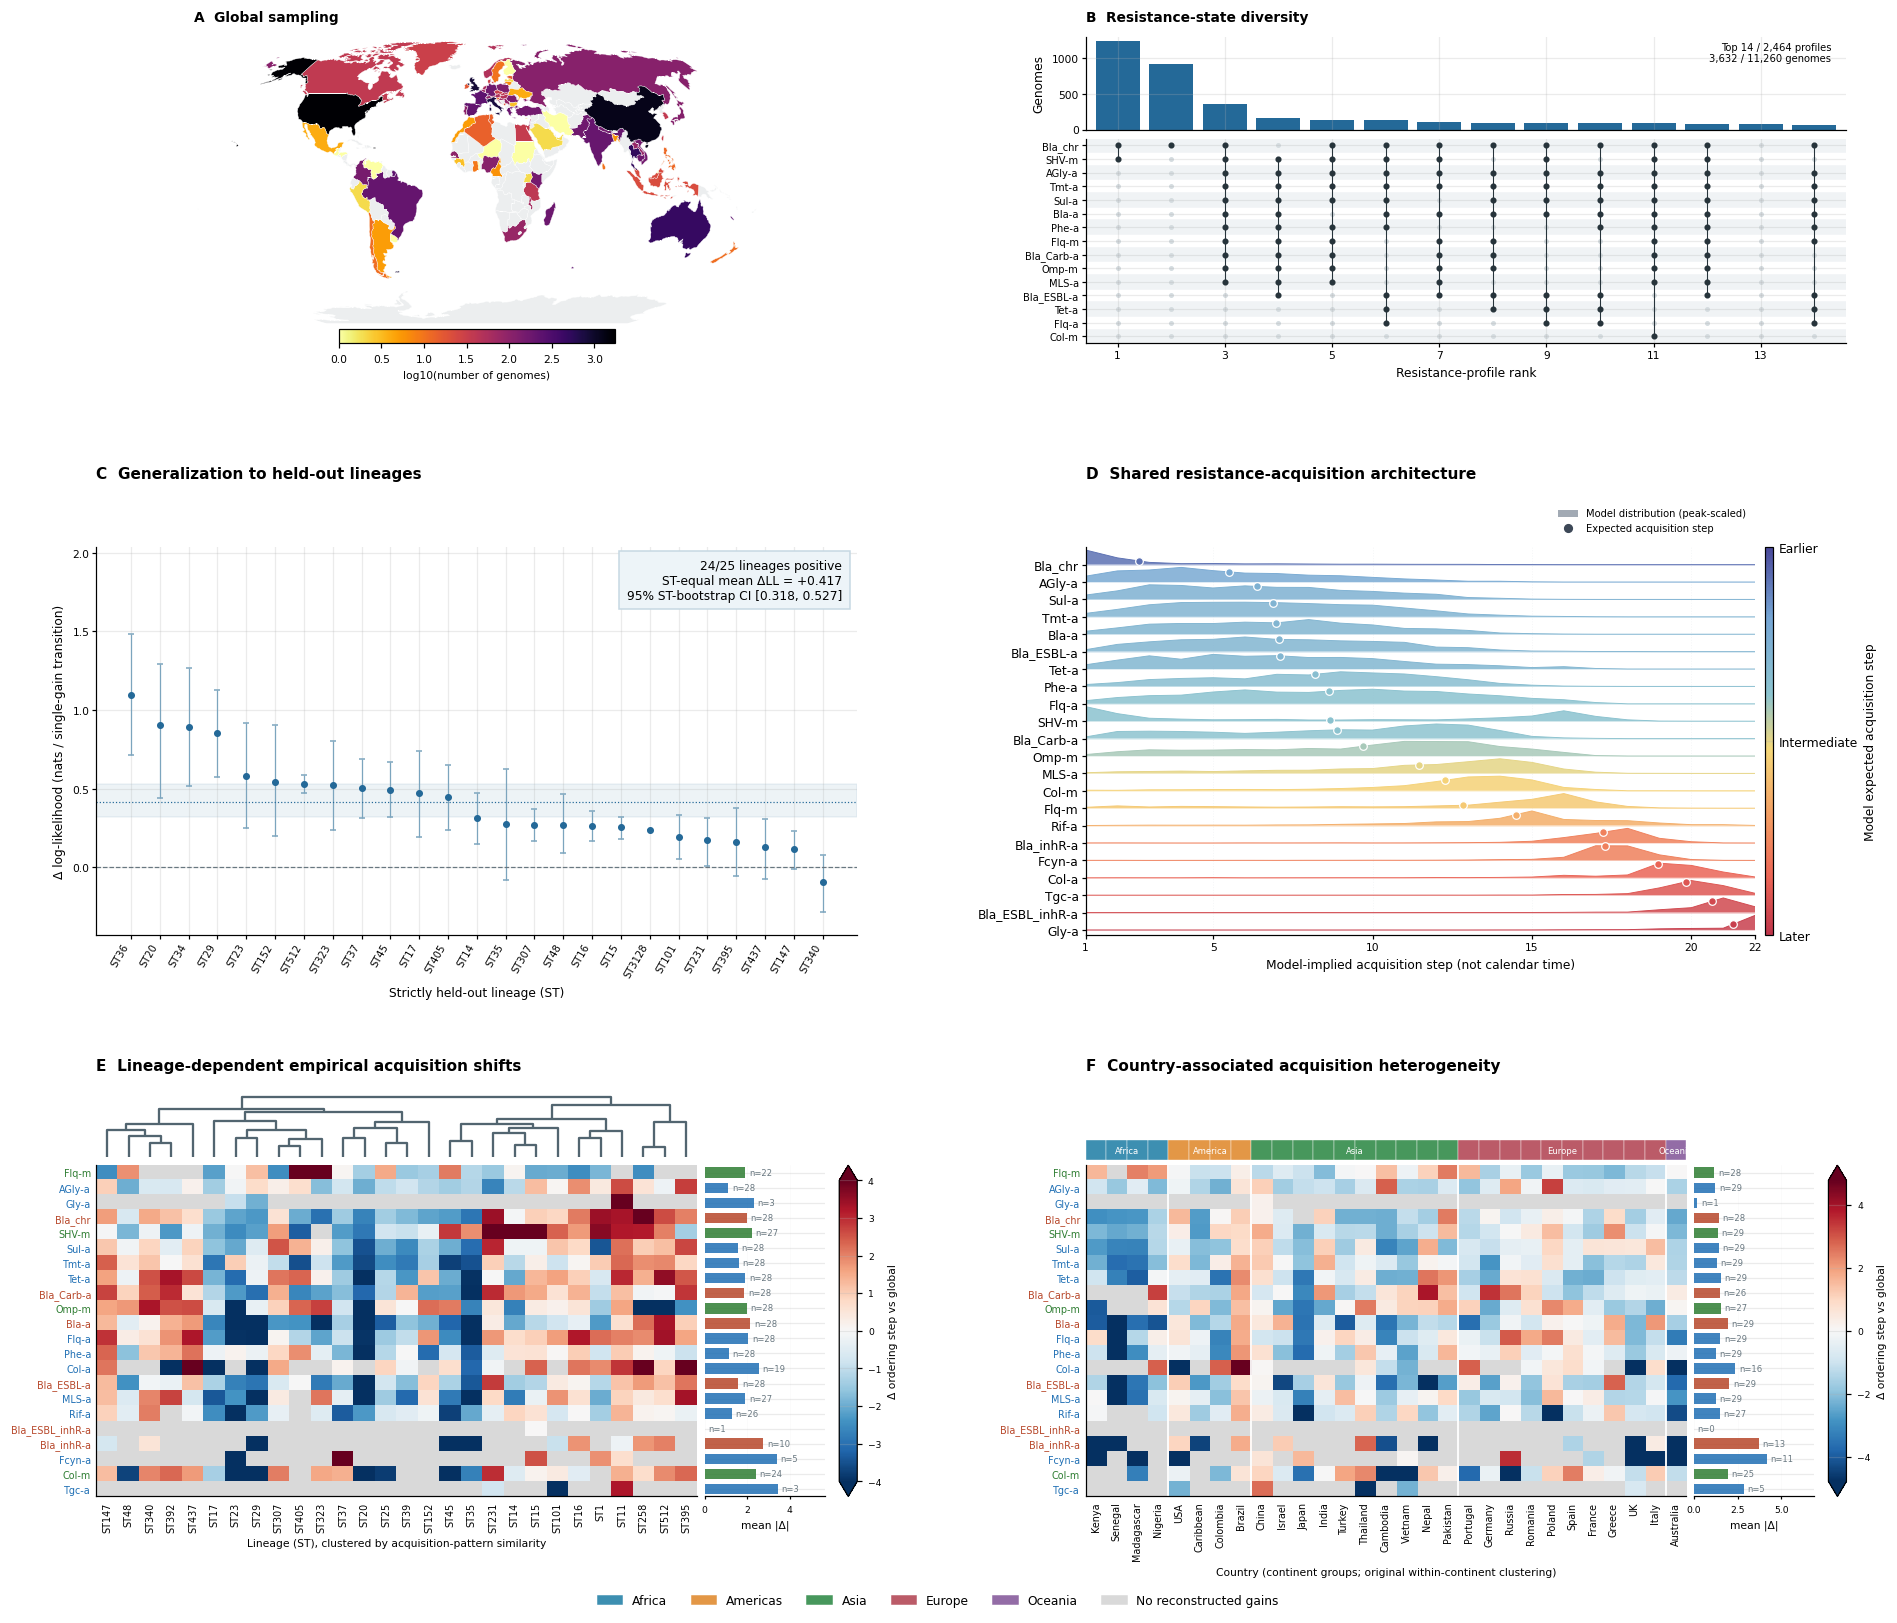

Map-unmapped / unknown-location genomes: 797


In [6]:
fig = plt.figure(figsize=(17.2, 15.8))
grid = fig.add_gridspec(3, 2, left=.055, right=.98, bottom=.085, top=.925, width_ratios=[1, 1], height_ratios=[3.0, 4.6, 4.3], wspace=.30, hspace=.30)
ax_map = fig.add_subplot(grid[0, 0], projection=ccrs.Robinson())
MAP_MATCHED = map_panel(ax_map, COUNTS)
title(ax_map, 'A', 'Global sampling')
ax_up, _ = upset(fig, grid[0, 1], n=14)
title(ax_up, 'B', 'Resistance-state diversity')
middle_grid = grid[1, :].subgridspec(2, 2, width_ratios=[1, 1], height_ratios=[.16, 1], wspace=.30, hspace=.09)
for column, letter, heading in [(0, 'C', 'Generalization to held-out lineages'), (1, 'D', 'Shared resistance-acquisition architecture')]:
    heading_ax = fig.add_subplot(middle_grid[0, column])
    heading_ax.axis('off')
    heading_ax.text(0, .85, f'{letter}  {heading}', fontsize=10, fontweight='bold', va='center')
ax_b = fig.add_subplot(middle_grid[1, 0])
performance(ax_b)
c_body = middle_grid[1, 1].subgridspec(1, 2, width_ratios=[.88, .12], wspace=0)
ax_global = global_distributions(fig, c_body[0])
bottom_grid = grid[2, :].subgridspec(2, 2, width_ratios=[1, 1], height_ratios=[.27, 1], wspace=.30, hspace=.09)
for column, letter, heading in [(0, 'E', 'Lineage-dependent empirical acquisition shifts'), (1, 'F', 'Country-associated acquisition heterogeneity')]:
    heading_ax = fig.add_subplot(bottom_grid[0, column])
    heading_ax.axis('off')
    heading_ax.text(0, .9, f'{letter}  {heading}', transform=heading_ax.transAxes, fontsize=10, fontweight='bold', va='center')
ax_d = fig.add_subplot(bottom_grid[1, 0])
heatmap(ax_d, LDEV, label='Lineage (ST), clustered by acquisition-pattern similarity', fontsize=6.3, support=LIN_SUPPORT)
tree_ax = ax_d.inset_axes([0, 1.025, 1, .19])
tree = dendrogram(LINEAGE_LINKAGE, ax=tree_ax, no_labels=True, color_threshold=0, above_threshold_color='#526570')
assert [CLUSTER_ST_LABELS[i] for i in tree['leaves']] == list(LDEV.columns)
tree_ax.set_xlim(0, 10 * len(LDEV.columns))
tree_ax.set_xticks([])
tree_ax.set_yticks([])
tree_ax.grid(False)
for spine in tree_ax.spines.values():
    spine.set_visible(False)
p_ari = CLUSTER_TEST['p_value']
ari = CLUSTER_TEST['ari']
ax_e = fig.add_subplot(bottom_grid[1, 1])
image_e = heatmap(ax_e, COUNTRY_MAIN, label='Country (continent groups; original within-continent clustering)', continent=True, fontsize=6.3, vmax=COUNTRY_VMAX, support=C_SUPPORT)
assert np.allclose(image_e.get_array().filled(np.nan), OLD_CDEV.loc[COUNTRY_MAIN.index, COUNTRY_ORDER], equal_nan=True)
assert np.array_equal(np.ma.getmaskarray(image_e.get_array()), OLD_CDEV.loc[COUNTRY_MAIN.index, COUNTRY_ORDER].isna().to_numpy())
assert np.allclose(image_e.get_clim(), [-COUNTRY_VMAX, COUNTRY_VMAX])
fig.legend(handles=[Patch(color=c, label='Americas' if k == 'America' else k) for k, c in CONT_COLORS.items() if k in set(CONTINENT.values())] + [Patch(color='#D9D9D9', label='No reconstructed gains')], loc='lower center', bbox_to_anchor=(.5, .015), ncol=6, frameon=False, fontsize=8)
fig.canvas.draw()
assert np.allclose([ax_b.get_position().y0, ax_b.get_position().height], [ax_global.get_position().y0, ax_global.get_position().height], atol=1e-8)
d_bounds = ax_d.get_position().bounds
e_bounds = ax_e.get_position().bounds
assert np.allclose(d_bounds[1:], e_bounds[1:], atol=1e-8), (d_bounds, e_bounds)
finish(fig, 'figure4_main_A-F')
UNMAPPED = COUNTS[~COUNTS.key.isin(MAP_MATCHED)]
export(UNMAPPED, 'map_unmapped_locations')
print('Map-unmapped / unknown-location genomes:', int(UNMAPPED.n_genomes.sum()))

## 6. Supplementary Figure S1 | Sampling structure and resistance-state diversity

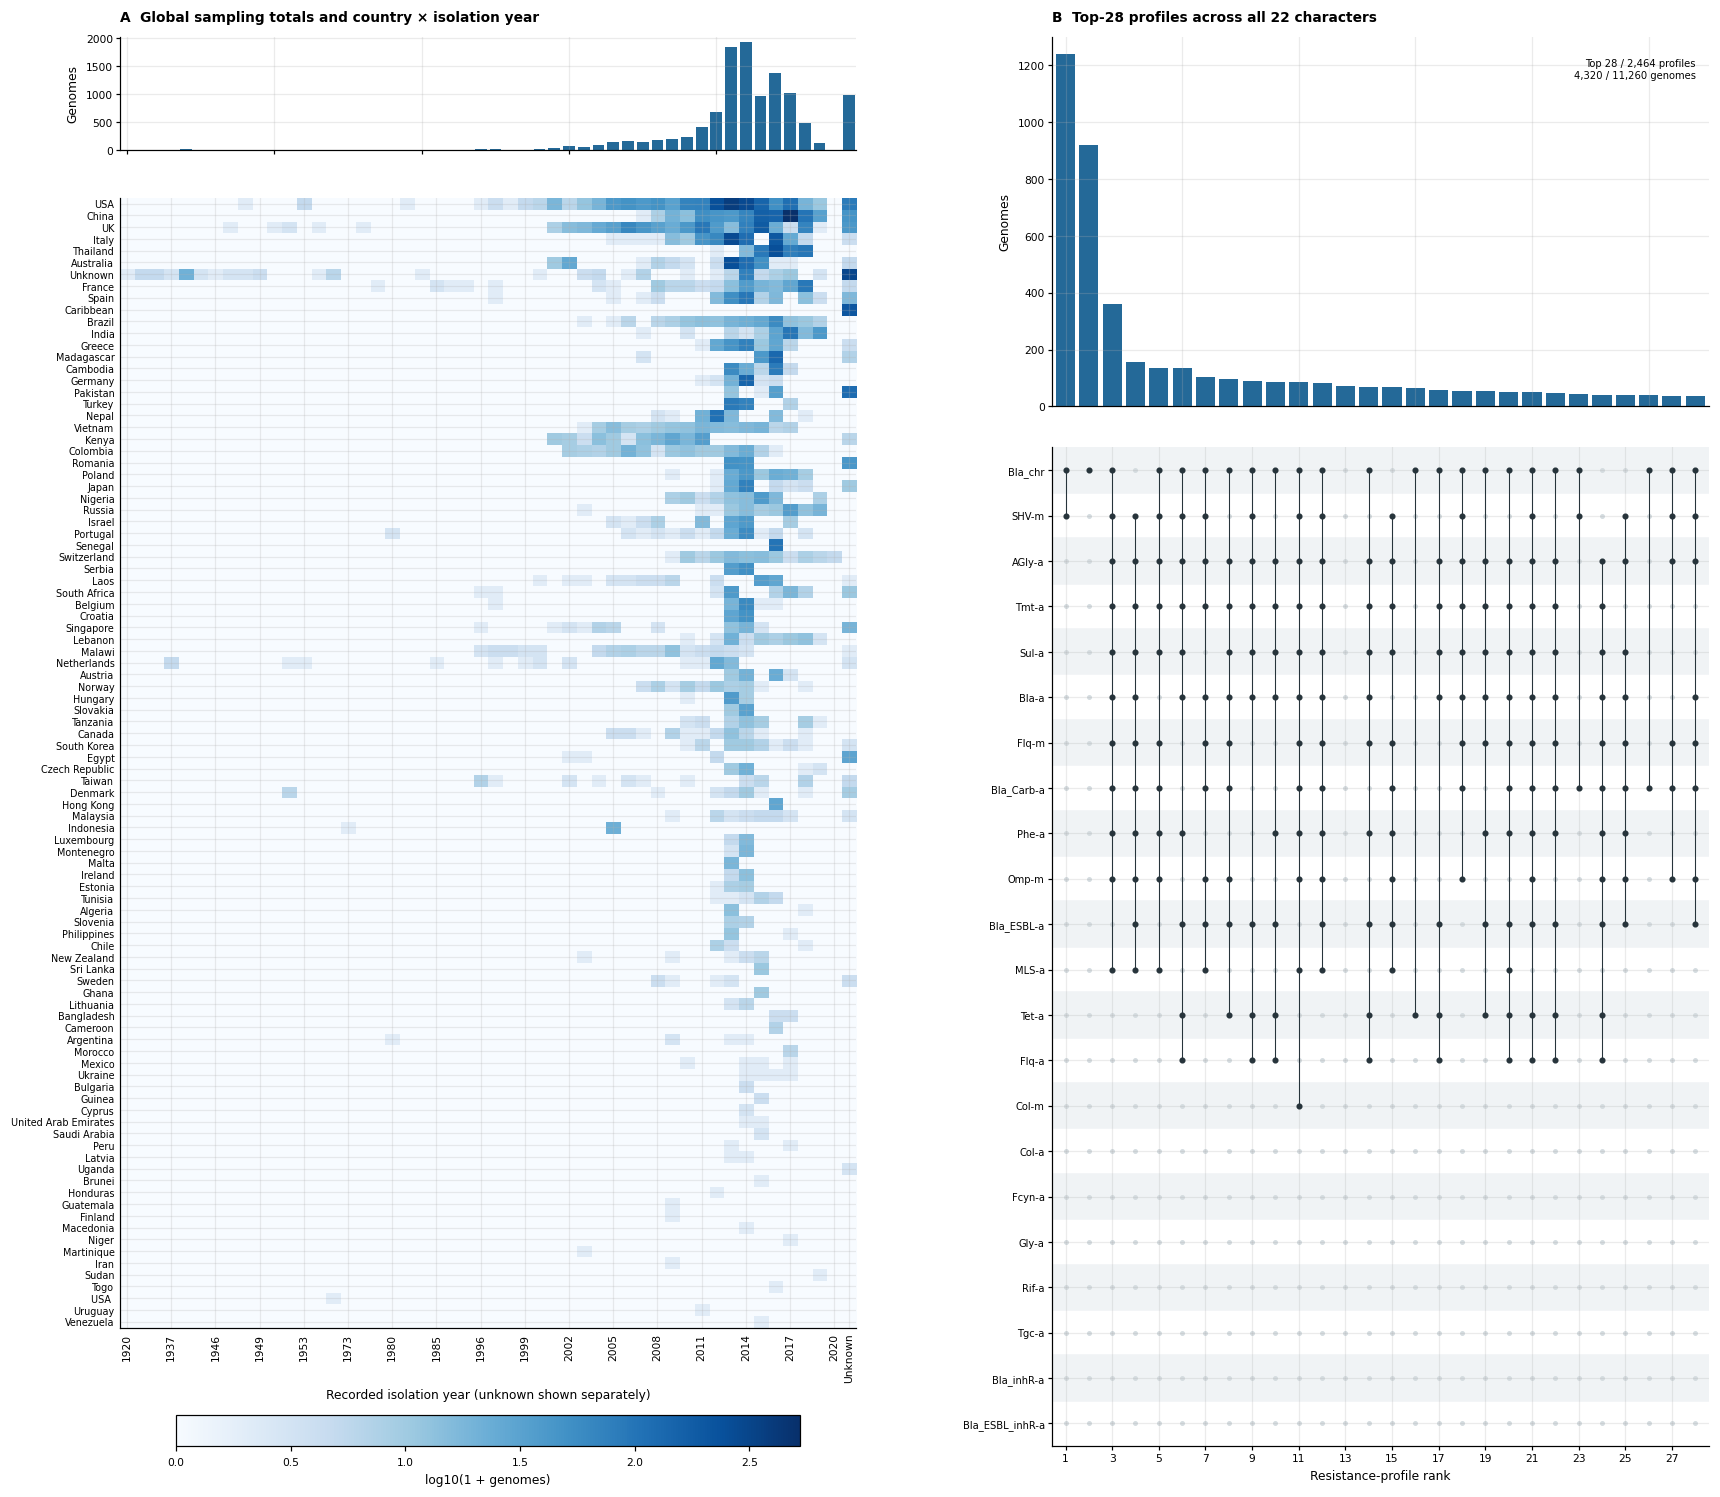

In [7]:
country_order = COUNTS.key.tolist()
year_frame = YEARS.reindex(country_order, fill_value=0).copy()
year_frame.columns = [str(int(y)) for y in year_frame.columns]
year_frame['Unknown'] = UNKNOWN_YEARS.reindex(country_order, fill_value=0)
assert int(year_frame.to_numpy().sum()) == len(SAMPLES)
fig = plt.figure(figsize=(17, max(12, .14 * len(country_order) + 2)))
grid = fig.add_gridspec(1, 2, left=.12, right=.97, top=.91, bottom=.08, width_ratios=[1.12, 1], wspace=.28)
g_left = grid[0].subgridspec(2, 1, height_ratios=[1, 11], hspace=.07)
ax_year = fig.add_subplot(g_left[0])
ax_year.bar(range(year_frame.shape[1]), year_frame.sum(0), color=BLUE)
ax_year.set_xlim(-.5, year_frame.shape[1] - .5)
ax_year.tick_params(axis='x', labelbottom=False)
ax_year.set_ylabel('Genomes')
title(ax_year, 'A', 'Global sampling totals and country × isolation year')
tidy(ax_year)
ax_yearmap = fig.add_subplot(g_left[1])
im = ax_yearmap.imshow(np.log10(1 + year_frame), aspect='auto', cmap='Blues', interpolation='nearest')
ax_yearmap.set_yticks(range(len(year_frame)), year_frame.index, fontsize=6.3)
ticks = sorted(set(list(range(0, year_frame.shape[1], 3)) + [year_frame.shape[1] - 1]))
ax_yearmap.set_xticks(ticks, year_frame.columns[ticks], rotation=90)
ax_yearmap.tick_params(length=0)
ax_yearmap.set_xlabel('Recorded isolation year (unknown shown separately)')
cb = fig.colorbar(im, ax=ax_yearmap, orientation='horizontal', fraction=.025, pad=.07)
cb.set_label('log10(1 + genomes)')
ax_profiles, _ = upset(fig, grid[1], n=28, full=True)
title(ax_profiles, 'B', 'Top-28 profiles across all 22 characters')
finish(fig, 'supplement_S1_sampling_profiles')

## 7. Supplementary Figure S2 | Robustness of cross-lineage generalization

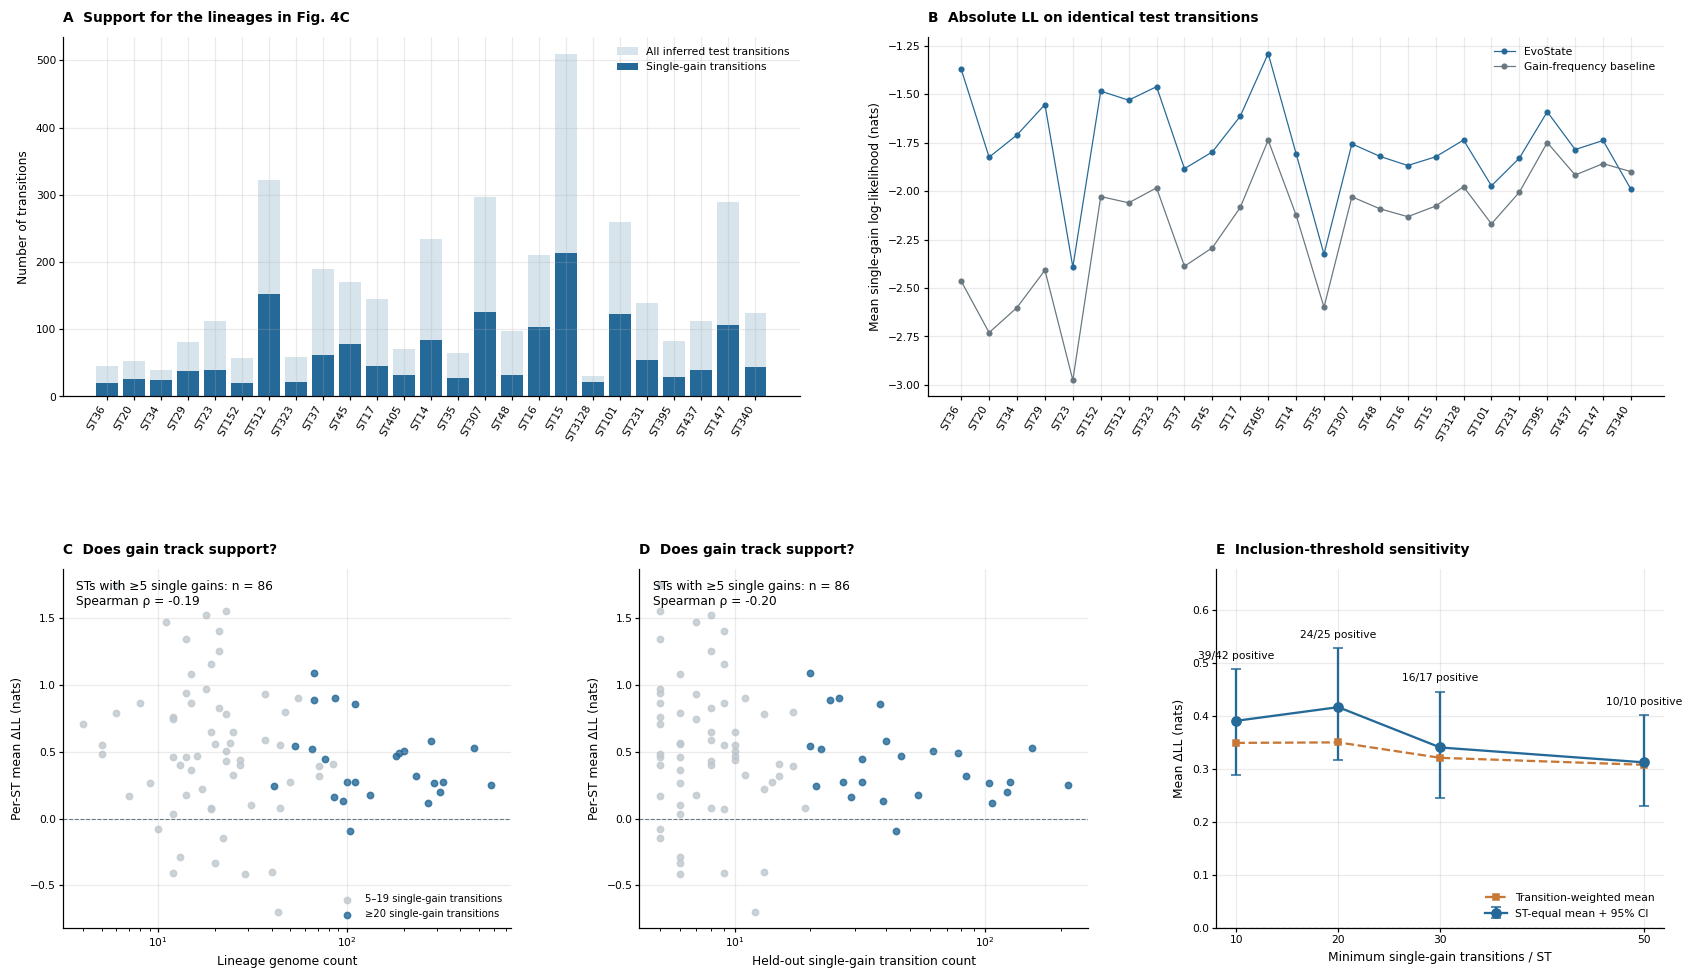

In [8]:
fig = plt.figure(figsize=(16, 10))
g = fig.add_gridspec(2, 6, left=.07, right=.98, top=.90, bottom=.09, hspace=.48, wspace=.8)
axes = [fig.add_subplot(g[0, :3]), fig.add_subplot(g[0, 3:]), fig.add_subplot(g[1, :2]), fig.add_subplot(g[1, 2:4]), fig.add_subplot(g[1, 4:])]
x = np.arange(len(MAIN_B))
a = axes[0]
a.bar(x, MAIN_B.n_edges, color='#d8e4ec', label='All inferred test transitions')
a.bar(x, MAIN_B.n_single, color=BLUE, label='Single-gain transitions')
a.set_xticks(x, MAIN_B.ST, rotation=60, ha='right')
a.set_ylabel('Number of transitions')
a.legend(frameon=False, fontsize=7)
title(a, 'A', 'Support for the lineages in Fig. 4C')
a = axes[1]
a.plot(x, MAIN_B.logl_evo, 'o-', color=BLUE, ms=3, lw=.8, label='EvoState')
a.plot(x, MAIN_B.logl_baseline, 'o-', color=GREY, ms=3, lw=.8, label='Gain-frequency baseline')
a.set_xticks(x, MAIN_B.ST, rotation=60, ha='right')
a.set_ylabel('Mean single-gain log-likelihood (nats)')
a.legend(frameon=False, fontsize=7)
title(a, 'B', 'Absolute LL on identical test transitions')
for a, field, label, letter, result in zip(axes[2:4], ['n_genomes', 'n_single'], ['Lineage genome count', 'Held-out single-gain transition count'], ['C', 'D'], CORRELATIONS):
    low = SCATTER_ST.n_single < MIN_SINGLE
    for mask, color, text in [(low, '#bfc8ce', '5–19 single-gain transitions'), (~low, BLUE, '≥20 single-gain transitions')]:
        f = SCATTER_ST[mask]
        a.scatter(f[field], f.gain, color=color, s=17, alpha=.8, label=text)
    a.set_xscale('log')
    a.axhline(0, color=GREY, lw=.7, ls='--')
    a.set(xlabel=label, ylabel='Per-ST mean ΔLL (nats)')
    title(a, letter, 'Does gain track support?')
    a.text(.03, .97, f'STs with ≥5 single gains: n = {result["n_ST"]}\nSpearman ρ = {result["spearman_rho"]:.2f}', transform=a.transAxes, va='top', fontsize=8)
    if letter == 'C':
        a.legend(frameon=False, fontsize=6.5, loc='lower right')
a = axes[4]
s = SENSITIVITY
a.errorbar(s.minimum_single, s.ST_equal_mean, yerr=[s.ST_equal_mean - s.ci_low, s.ci_high - s.ST_equal_mean], fmt='o-', color=BLUE, capsize=3, label='ST-equal mean + 95% CI')
a.plot(s.minimum_single, s.edge_weighted_mean, 's--', color=ORANGE, ms=4, label='Transition-weighted mean')
for row in s.itertuples():
    a.annotate(f'{row.n_positive}/{row.n_ST} positive', (row.minimum_single, row.ci_high), xytext=(0, 7), textcoords='offset points', ha='center', fontsize=7)
a.axhline(0, color=GREY, ls='--', lw=.8)
a.set_xticks(s.minimum_single)
a.set(xlabel='Minimum single-gain transitions / ST', ylabel='Mean ΔLL (nats)', ylim=(min(0, s.ci_low.min() - .05), s.ci_high.max() + .15))
a.legend(frameon=False, fontsize=7, loc='lower right')
title(a, 'E', 'Inclusion-threshold sensitivity')
for a in axes:
    tidy(a)
finish(fig, 'supplement_S2_lineage_generalization')

## 8. Supplementary Figure S3 | Full lineage-specific acquisition-order distributions

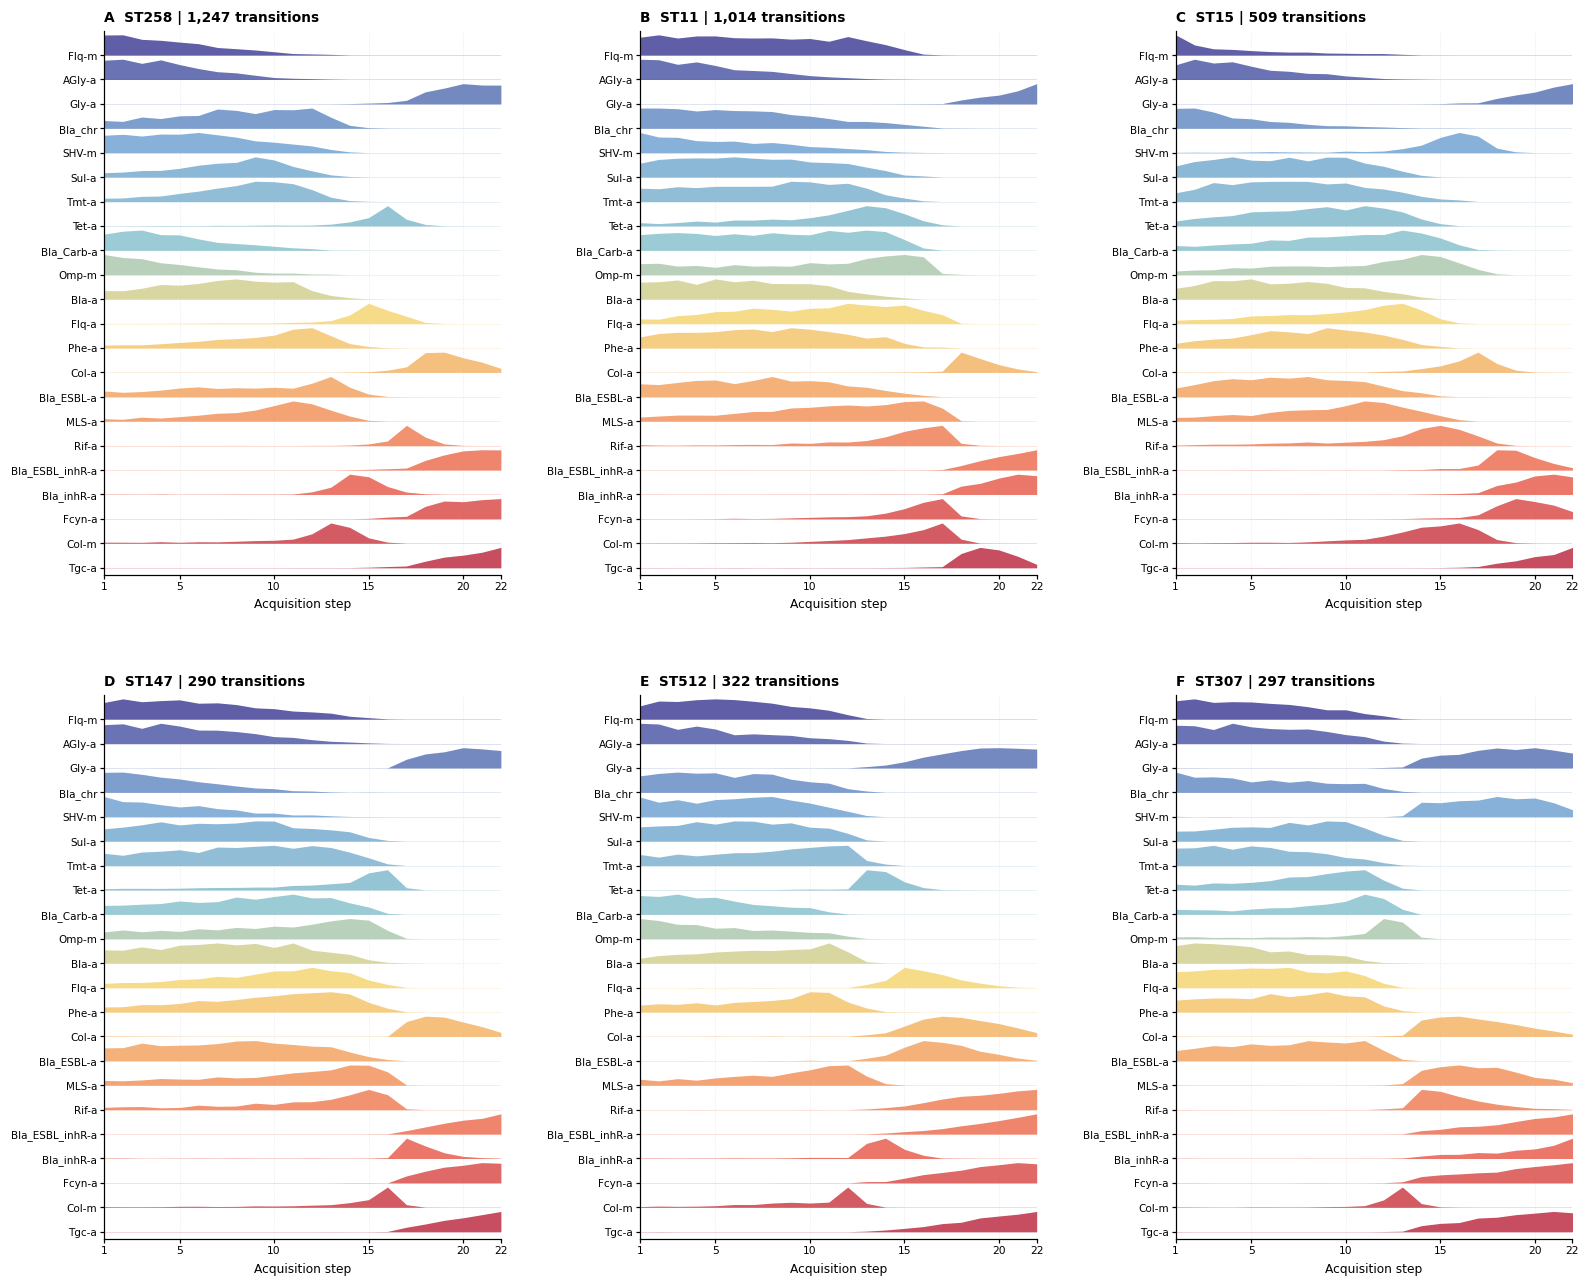

In [9]:
MODEL_PROVENANCE = []

def model_bubble(group, kind):
    checkpoint = ROOT / 'checkpoints' / f'klebsiella_kleborate22_{kind}_{group}' / 'model.pt'
    cache_path = CACHE / f'{kind}_{group}_walks.csv'
    stamp_path = CACHE / f'{kind}_{group}_walks.json'
    fingerprint = {'checkpoint_sha256': digest(track(checkpoint)), 'n_walks': N_WALKS, 'seed': 1, 'features': FEATURES, 'protocol': 'hc.bubble_from_scorer; zero start; gain-only; complete L steps', 'inference_code_sha256': digest(BASE / 'models/two_stage_backbone.py'), 'walk_code_sha256': digest(BASE / 'analysis_repr_evo/hypertraps_compare.py')}
    if cache_path.exists() and stamp_path.exists() and json.loads(stamp_path.read_text()) == fingerprint:
        bubble = read_csv(cache_path, index_col=0).reindex(FEATURES)
        status = 'validated local cache'
    else:
        print(f'Forward walks from existing {kind} model: {group}', flush=True)
        import torch
        torch.set_num_threads(2)
        model = st.load_two_stage_model(str(checkpoint))
        score = hc.two_stage_scorer(model)
        @lru_cache(maxsize=50000)
        def cached_score(state_bytes):
            return tuple(score(np.frombuffer(state_bytes, dtype=np.int8)))
        bubble = hc.bubble_from_scorer(lambda state: np.array(cached_score(state.astype(np.int8).tobytes())), FEATURES, n_walks=N_WALKS, seed=1)
        check_bubble(bubble, complete=True)
        bubble.to_csv(cache_path)
        stamp_path.write_text(json.dumps(fingerprint, indent=2))
        status = 'existing checkpoint; no training'
    check_bubble(bubble, complete=True)
    MODEL_PROVENANCE.append({'kind': kind, 'group': group, 'source': str(checkpoint.relative_to(ROOT)), 'status': status, 'n_walks': N_WALKS, 'seed': 1})
    return bubble

ST_MODELS, ST_EMP = {}, {}
for group in TOP_ST:
    ST_MODELS[group] = model_bubble(group, 'lineage')
    if group not in set(GROUP):
        raise ValueError(f'No empirical transitions for {group}')
    indices = np.flatnonzero(GROUP == group)
    subset = st.TransitionSet(frame=TS.frame.iloc[indices].reset_index(drop=True), src=TS.src[indices], dest=TS.dest[indices], gained=[TS.gained[i] for i in indices], feature_names=FEATURES)
    ST_EMP[group] = st.empirical_bubble_matrix(subset)
    export(ST_MODELS[group], f'S3_{group}_model_distribution', index=True)
    export(ST_EMP[group], f'S3_{group}_empirical_distribution', index=True)
fig, axes = plt.subplots(2, 3, figsize=(15, 13))
for letter, ax, group in zip('ABCDEF', axes.flat, TOP_ST):
    ridge(ax, ST_MODELS[group], f'{letter}  {group} | {int((GROUP == group).sum()):,} transitions')
fig.subplots_adjust(left=.09, right=.98, top=.905, bottom=.06, wspace=.35, hspace=.22)
finish(fig, 'supplement_S3_lineage_distributions')

## 9. Supplementary Figure S4 | Complete country-associated heterogeneity

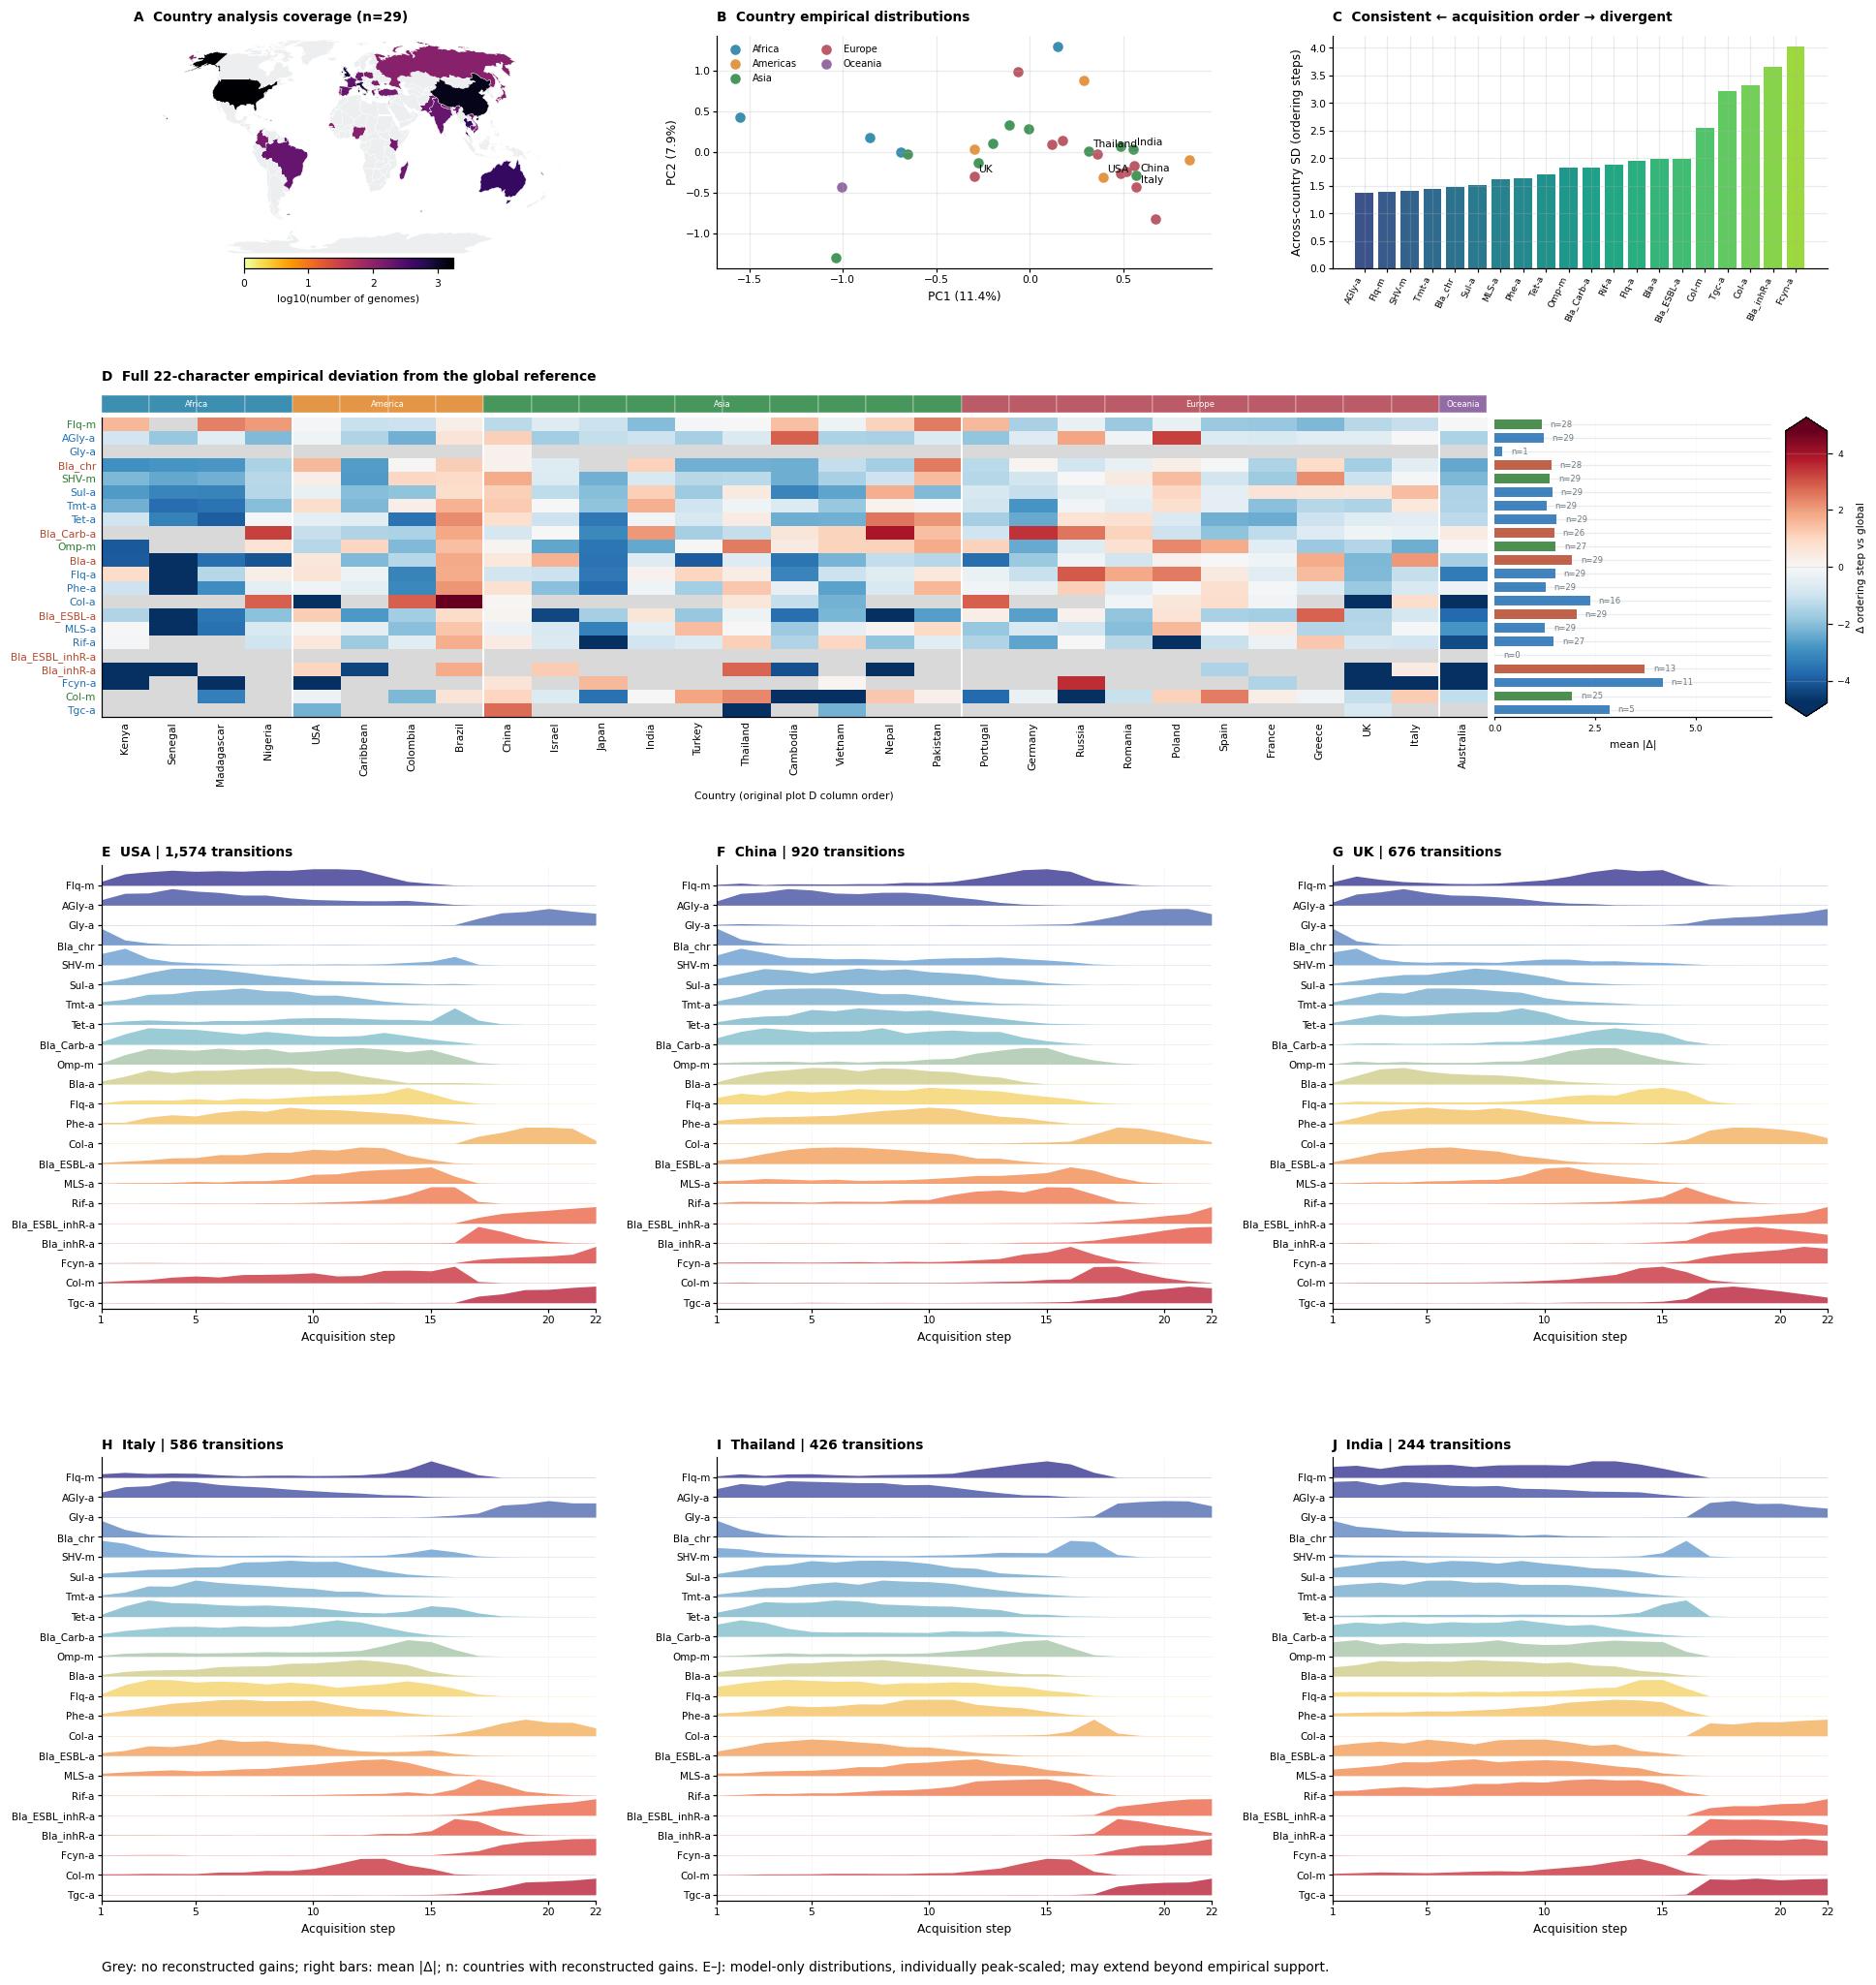

In [10]:
COUNTRY_MODELS = {}
for country in TOP_COUNTRY:
    path = OLD / f'country_{country}_bubble_TS_country.csv'
    if path.exists():
        bubble = read_csv(path, index_col=0).reindex(FEATURES)
        check_bubble(bubble, complete=True)
        COUNTRY_MODELS[country] = bubble
        MODEL_PROVENANCE.append({'kind': 'country', 'group': country, 'source': str(path.relative_to(ROOT)), 'status': 'legacy country-specific cache; checkpoint/seed binding not recorded', 'n_walks': None, 'seed': None})
    else:
        COUNTRY_MODELS[country] = model_bubble(country, 'country')
    export(COUNTRY_MODELS[country], f'S4_{country}_model_distribution', index=True)
    export(COUNTRY_BUBBLES[country], f'S4_{country}_empirical_distribution', index=True)
CONSISTENCY = pd.DataFrame({'sd_expected_step': CDEV.std(axis=1), 'n_supported_countries': CDEV.notna().sum(axis=1)})
CONSISTENCY = CONSISTENCY[CONSISTENCY.n_supported_countries >= 5].sort_values('sd_expected_step')
export(CONSISTENCY, 'country_character_consistency', index=True)
fig = plt.figure(figsize=(18, 20))
g = fig.add_gridspec(4, 6, left=.07, right=.97, top=.92, bottom=.045, height_ratios=[1.05, 1.35, 2, 2], hspace=.42, wspace=.65)
ax = fig.add_subplot(g[0, :2], projection=ccrs.Robinson())
coverage = COUNTS[COUNTS.key.isin(CMETA.key)]
map_panel(ax, coverage)
title(ax, 'A', f'Country analysis coverage (n={len(CMETA)})')
ax = fig.add_subplot(g[0, 2:4])
for continent, color in CONT_COLORS.items():
    names = [c for c in CSCORES.index if CONTINENT.get(c) == continent]
    if names:
        ax.scatter(CSCORES.loc[names, 'PC1'], CSCORES.loc[names, 'PC2'], s=35, color=color, label='Americas' if continent == 'America' else continent)
for country in TOP_COUNTRY:
    ax.annotate(country, CSCORES.loc[country, ['PC1', 'PC2']], xytext=(3, 3), textcoords='offset points', fontsize=7)
ax.set(xlabel=f'PC1 ({CEVR[0]:.1%})', ylabel=f'PC2 ({CEVR[1]:.1%})')
ax.legend(frameon=False, fontsize=6.5, ncol=2)
title(ax, 'B', 'Country empirical distributions')
tidy(ax)
ax = fig.add_subplot(g[0, 4:])
x = np.arange(len(CONSISTENCY))
ax.bar(x, CONSISTENCY.sd_expected_step, color=plt.get_cmap('viridis')(np.linspace(.25, .85, len(x))))
ax.set_xticks(x, [SHORT[f] for f in CONSISTENCY.index], rotation=65, ha='right', fontsize=6)
ax.set_ylabel('Across-country SD (ordering steps)')
title(ax, 'C', 'Consistent ← acquisition order → divergent')
tidy(ax)
ax = fig.add_subplot(g[1, :])
heatmap(ax, CDEV, label='Country (original plot D column order)', continent=True, fontsize=7, vmax=COUNTRY_VMAX, support=C_SUPPORT)
title(ax, 'D', 'Full 22-character empirical deviation from the global reference')
for j, country in enumerate(TOP_COUNTRY):
    ax = fig.add_subplot(g[2 + j // 3, (j % 3) * 2:(j % 3) * 2 + 2])
    support = int(C_AUDIT.loc[country, 'n_transitions'])
    ridge(ax, COUNTRY_MODELS[country], f'{chr(69 + j)}  {country} | {support:,} transitions')
fig.text(.07, .012, f'Grey: no reconstructed gains; right bars: mean |Δ|; n: countries with reconstructed gains. E–J: model-only distributions, individually peak-scaled; may extend beyond empirical support.', fontsize=9)
finish(fig, 'supplement_S4_country_heterogeneity')